In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [46]:
df = pd.read_csv("train.csv",usecols=['Survived','Age','Fare','SibSp','Parch'])

df.head()

,Survived,Age,SibSp,Parch,Fare
0,0,22.0,1,0,7.2500
1,1,38.0,1,0,71.2833
2,1,26.0,0,0,7.9250
3,1,35.0,1,0,53.1000
4,0,35.0,0,0,8.0500


In [47]:
df['Family'] = np.where(df['SibSp'] + df['Parch'] > 0,1,0)

df.head()

,Survived,Age,SibSp,Parch,Fare,Family
0,0,22.0,1,0,7.2500,1
1,1,38.0,1,0,71.2833,1
2,1,26.0,0,0,7.9250,0
3,1,35.0,1,0,53.1000,1
4,0,35.0,0,0,8.0500,0


In [48]:
df.drop(columns=['Parch','SibSp'])

,Survived,Age,Fare,Family
0,0,22.0,7.2500,1
1,1,38.0,71.2833,1
2,1,26.0,7.9250,0
3,1,35.0,53.1000,1
4,0,35.0,8.0500,0
...,...,...,...,...
886,0,27.0,13.0000,0
887,1,19.0,30.0000,0
888,0,NaN,23.4500,1
889,1,26.0,30.0000,0


In [49]:
df.head()

,Survived,Age,SibSp,Parch,Fare,Family
0,0,22.0,1,0,7.2500,1
1,1,38.0,1,0,71.2833,1
2,1,26.0,0,0,7.9250,0
3,1,35.0,1,0,53.1000,1
4,0,35.0,0,0,8.0500,0


In [50]:
df.isnull().sum()

Survived      0
Age         180
SibSp         0
Parch         0
Fare         33
Family        0
dtype: int64

In [51]:
X = df.drop(columns='Survived')
y = df['Survived']


In [52]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [53]:
X_train.shape,X_test.shape

((712, 5), (179, 5))

In [54]:
X_train.isnull().mean()

Age       0.199438
SibSp     0.000000
Parch     0.000000
Fare      0.037921
Family    0.000000
dtype: float64

In [55]:
mean_age = X_train['Age'].mean()
median_age = X_train['Age'].median()

mean_fare = X_train['Fare'].mean()
median_fare = X_train['Fare'].median()

In [56]:
X_train["Age_mean"] = X_train["Age"].fillna(mean_age)
X_train["Age_median"] = X_train["Age"].fillna(median_age)

X_train["Fare_mean"] = X_train["Fare"].fillna(mean_fare)
X_train["Fare_median"] = X_train["Fare"].fillna(median_fare)

X_train.sample(5)

,Age,SibSp,Parch,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
474,22.0,0,0,9.8375,0,22.000,22.0,9.8375,9.8375
46,NaN,1,0,15.5000,1,29.562,28.0,15.5000,15.5000
92,46.0,1,0,61.1750,1,46.000,46.0,61.1750,61.1750
95,NaN,0,0,8.0500,0,29.562,28.0,8.0500,8.0500
609,40.0,0,0,153.4625,0,40.000,40.0,153.4625,153.4625


In [57]:
print("Original Age variance: ", X_train["Age"].var())
print("Age variance after median imputation: ", X_train["Age_median"].var())
print("Age variance after mean imputation: ", X_train["Age_mean"].var())

Original Age variance:  209.53081637961333
Age variance after median imputation:  168.07369259865044
Age variance after mean imputation:  167.68359285513358


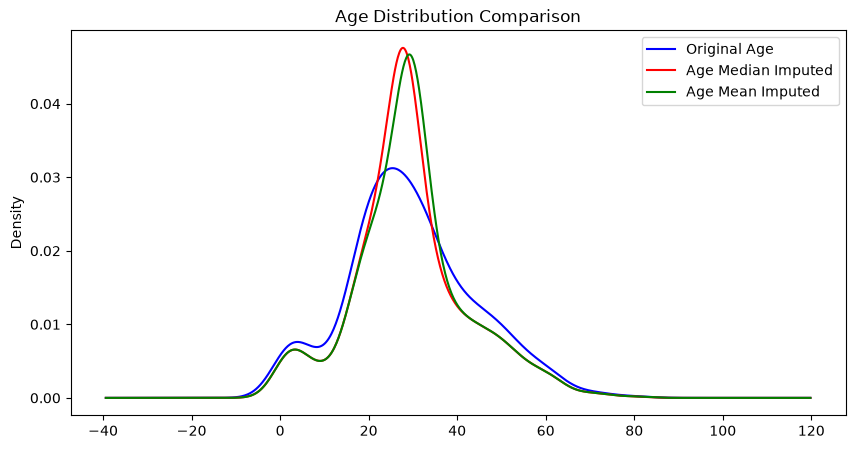

Covariance Matrix:
                     Age     SibSp     Parch         Fare    Family  \
Age          209.530816 -4.357301 -2.479121    62.099775 -1.488640   
SibSp         -4.357301  1.383927  0.410112     9.208415  0.333890   
Parch         -2.479121  0.410112  0.626740     9.425313  0.228808   
Fare          62.099775  9.208415  9.425313  2758.261388  6.658953   
Family        -1.488640  0.333890  0.228808     6.658953  0.239825   
Age_mean     209.530816 -3.487066 -1.983994    50.049715 -1.191331   
Age_median   209.530816 -3.516552 -1.931602    54.059273 -1.144227   
Fare_mean     60.165211  8.858729  9.067390  2758.261388  6.406081   
Fare_median   61.579037  8.601465  9.124648  2758.261388  6.373645   

               Age_mean  Age_median    Fare_mean  Fare_median  
Age          209.530816  209.530816    60.165211    61.579037  
SibSp         -3.487066   -3.516552     8.858729     8.601465  
Parch         -1.983994   -1.931602     9.067390     9.124648  
Fare          50.049715

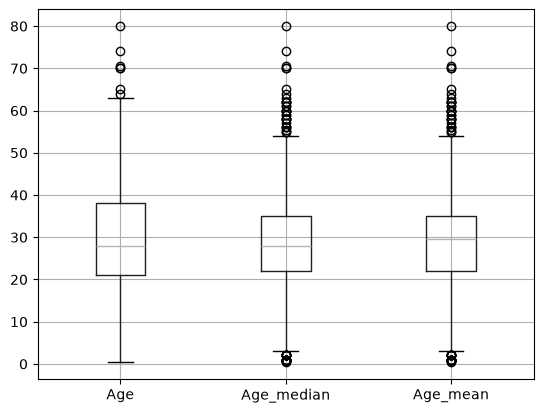

In [58]:
# 2. Distribution Plot Check (KDE)
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111)

X_train["Age"].plot(kind="kde", ax=ax, color="blue", label="Original Age")
X_train["Age_median"].plot(
    kind="kde", ax=ax, color="red", label="Age Median Imputed"
)
X_train["Age_mean"].plot(
    kind="kde", ax=ax, color="green", label="Age Mean Imputed"
)
plt.legend()
plt.title("Age Distribution Comparison")
plt.show()

# 3. Covariance & Correlation Check
print("Covariance Matrix:\n", X_train.cov())
print("Correlation Matrix:\n", X_train.corr())

# 4. Boxplot for Outliers Check
X_train[["Age", "Age_median", "Age_mean"]].boxplot()
plt.show()

Using Pipeline

In [59]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [61]:
imputer1 = SimpleImputer(strategy='median')
imputer2 = SimpleImputer(strategy='mean')

In [63]:
X_train.head()

,Age,SibSp,Parch,Fare,Family
331,45.5,0,0,28.5000,0
733,23.0,0,0,13.0000,0
382,32.0,0,0,7.9250,0
704,26.0,1,0,7.8542,1
813,6.0,4,2,31.2750,1


In [66]:
trf = ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare'])
],remainder='passthrough')

In [67]:
trf.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer1', ...), ('imputer2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and

In [69]:
trf.named_transformers_['imputer1'].statistics_

array([28.])

In [70]:
trf.named_transformers_['imputer2'].statistics_

array([32.58415372])

In [71]:
X_train = trf.transform(X_train)
X_test = trf.transform(X_test)